# Microdata choice training: overall transfer (`Table 1`, `Figure 1`, `Table A1`)

Population OLS $\mathrm{MSE}_\beta$ (`Table 1`, `Figure 1` exported to `manuscript/figures/fig_results_overall.{png,pdf}`) and held-out empirical cross-entropy (`Table A1`).

In [1]:
import sys
from pathlib import Path
from IPython.display import display

PAPER_DIR = next(
    (
        p
        for p in (
            Path.cwd(),
            *Path.cwd().parents,
            Path.cwd() / "train-notebooks" / "beta-training" / "ms_paper_beta_loss",
            Path.cwd() / "code" / "train-notebooks" / "beta-training" / "ms_paper_beta_loss",
        )
        if (p / "microdata_analysis.py").is_file()
    ),
    None,
)
if PAPER_DIR is None:
    raise FileNotFoundError(f"Could not locate microdata_analysis.py from {Path.cwd()}")
if str(PAPER_DIR) not in sys.path:
    sys.path.insert(0, str(PAPER_DIR))

import microdata_analysis as ma

ctx = ma.load_microdata_context()
print(f"Loaded {len(ctx.regimes_by_model)} models from {ma.PAPER_RUNS_ROOT}")


Loaded 3 models from /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-rorqual


In [2]:
ma.print_caption("Table 1", "Population β MSE after choice training")
display(ma.build_mse_styler(ctx.regimes_by_model, ma.MODEL_SLUGS, ma.ALL_SLUGS, ma.STORY_COLUMNS))
ma.print_note(
    "Values are population β MSE ×10³, with the percentage change versus Off-the-shelf in parentheses; lower is better. "
    "Bold marks the lowest trained value per model and column when it improves on Off-the-shelf. "
    f"{ma.ROLES_NOTE} NaN = held-out test evaluation not finished yet."
)


Table 1
Population β MSE after choice training


Note. Values are population β MSE ×10³, with the percentage change versus Off-the-shelf in parentheses; lower is better. Bold marks the lowest trained value per model and column when it improves on Off-the-shelf. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2026) are held-out test datasets; Flights (Goldfarb et al., 2026) is the validation dataset and selects each run's checkpoint (best.pt). NaN = held-out test evaluation not finished yet.


Figure 1
Choice training across datasets
Saved /home/dw/github/decision-models-finetuning/manuscript/figures/fig_results_overall.{png,pdf}


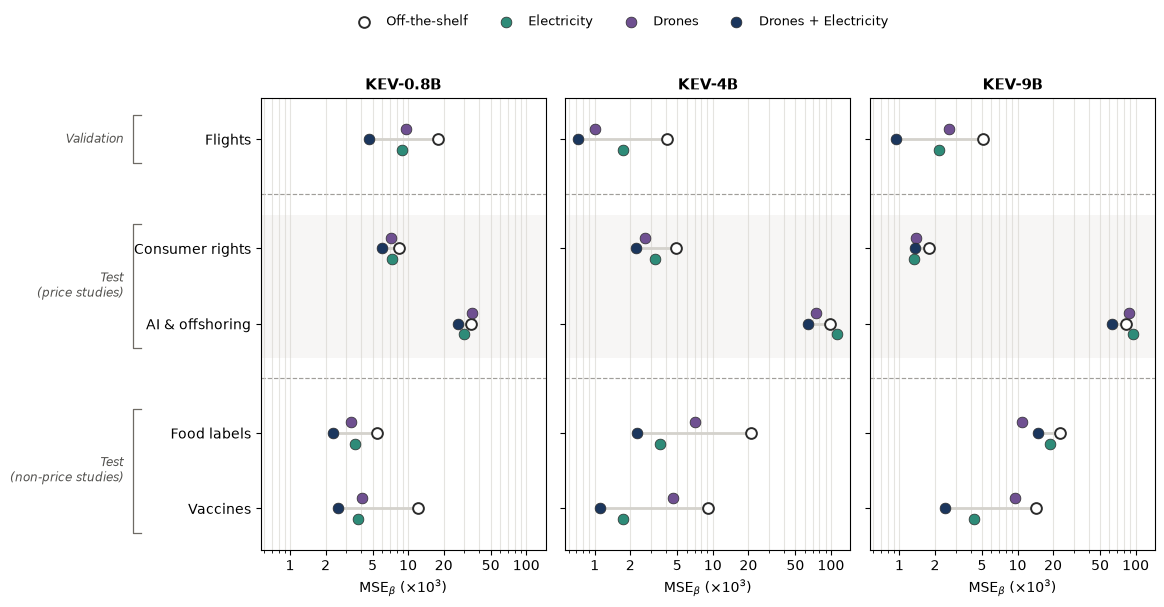

Note. Open circles are Off-the-shelf; filled circles are choice-trained regimes. Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Off-the-shelf to Drones + Electricity. Dashed horizontal dividers separate the validation dataset (top), held-out test price studies (middle), and held-out test non-price studies (bottom). Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2026) are held-out test datasets; Flights (Goldfarb et al., 2026) is the validation dataset and selects each run's checkpoint (best.pt). Missing points: held-out test evaluations not finished yet.


In [3]:
ma.print_caption("Figure 1", "Choice training across datasets")
ma.plot_dot_panels(
    regimes_by_model=ctx.regimes_by_model,
    models=ma.MODEL_SLUGS,
    slugs=ma.ALL_SLUGS,
    datasets=ma.STORY_COLUMNS,
    y_offsets={
        "row1_base_untrained": 0.0,
        "row2b_wu_ce_oracle": 0.14,
        "row3_berke_ce_only": -0.14,
        "row5_full_berke_wu_ce_oracle": 0.0,
    },
    x_ticks=(0.5, 1, 2, 5, 10, 20, 50, 100),
    scale="log",
    row_groups=ma.STORY_ROW_GROUPS,
    save_stem="fig_results_overall",
    reference_slug="row5_full_berke_wu_ce_oracle",
)
ma.print_note(
    "Open circles are Off-the-shelf; filled circles are choice-trained regimes. Population β MSE ×10³ on a shared log scale; lower is better. "
    "The grey bar joins Off-the-shelf to Drones + Electricity. "
    "Dashed horizontal dividers separate the validation dataset (top), held-out test price studies (middle), and held-out test non-price studies (bottom). "
    f"{ma.ROLES_NOTE} Missing points: held-out test evaluations not finished yet."
)


In [4]:
ce_values = ma.build_metric_table(ctx.regimes_by_model, ma.MODEL_SLUGS, ma.ALL_SLUGS, "kl", ma.STORY_COLUMNS)
ce_css = ma.relabel_rows(ma.best_cell_css(ce_values))
table_a1_styler = ma.relabel_rows(ce_values.round(3)).style.format("{:.3f}").apply(lambda _frame: ce_css, axis=None)
ma.print_caption("Table A1", "Empirical cross-entropy across datasets after choice training")
display(table_a1_styler)
ma.print_note(
    "Values report mean empirical cross-entropy (negative log-likelihood per choice task, in nats); lower is better. "
    "Uniform random guessing yields ln(2) = 0.693 on Flights and Consumer rights, ln(3) = 1.099 on Food labels and Vaccines, and ln(5) = 1.609 on AI & offshoring. "
    "Bold marks the lowest trained value per model and column when it improves on Off-the-shelf. "
    f"{ma.ROLES_NOTE}"
)


Table A1
Empirical cross-entropy across datasets after choice training


Note. Values report mean empirical cross-entropy (negative log-likelihood per choice task, in nats); lower is better. Uniform random guessing yields ln(2) = 0.693 on Flights and Consumer rights, ln(3) = 1.099 on Food labels and Vaccines, and ln(5) = 1.609 on AI & offshoring. Bold marks the lowest trained value per model and column when it improves on Off-the-shelf. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2026) are held-out test datasets; Flights (Goldfarb et al., 2026) is the validation dataset and selects each run's checkpoint (best.pt).
